In [ ]:
from google.colab import files

uploaded = files.upload()

Saving European_Bank (1).csv to European_Bank (1).csv


DATASET LOADED SUCCESSFULLY
--------------------------------------------------
File: European_Bank (1).csv
Rows: 10000
Columns: 14

Column Names:
['Year', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



DATA QUALITY REPORT
--------------------------------------------------


,Column,Data Type,Missing Values,Unique Values
0,Year,int64,0,1
1,CustomerId,int64,0,10000
2,Surname,object,0,2932
3,CreditScore,int64,0,460
4,Geography,object,0,3
5,Gender,object,0,2
6,Age,int64,0,70
7,Tenure,int64,0,11
8,Balance,float64,0,6382
9,NumOfProducts,int64,0,4


Exact duplicate rows: 0

OVERALL CUSTOMER CHURN


,Metric,Value
0,Total Customers,10000.00
1,Exited Customers,2037.00
2,Retained Customers,7963.00
3,Churn Rate (%),20.37
4,Retention Rate (%),79.63


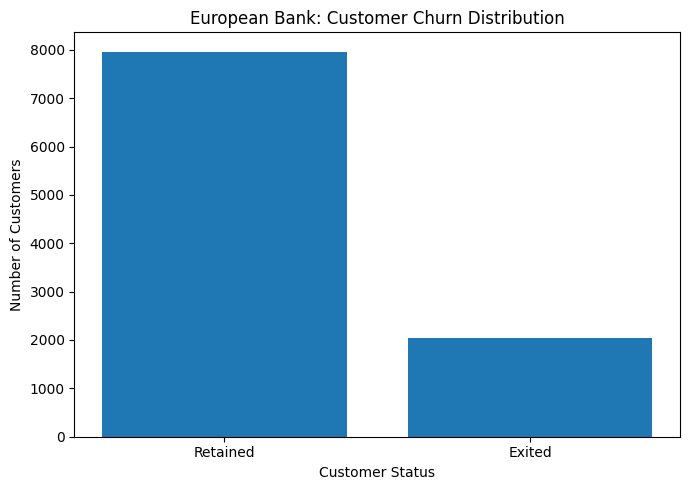


CHURN RATE BY GEOGRAPHY


,Geography,Customers,Exited,Retained,Churn Rate (%)
0,France,5014,810,4204,16.15
1,Germany,2509,814,1695,32.44
2,Spain,2477,413,2064,16.67


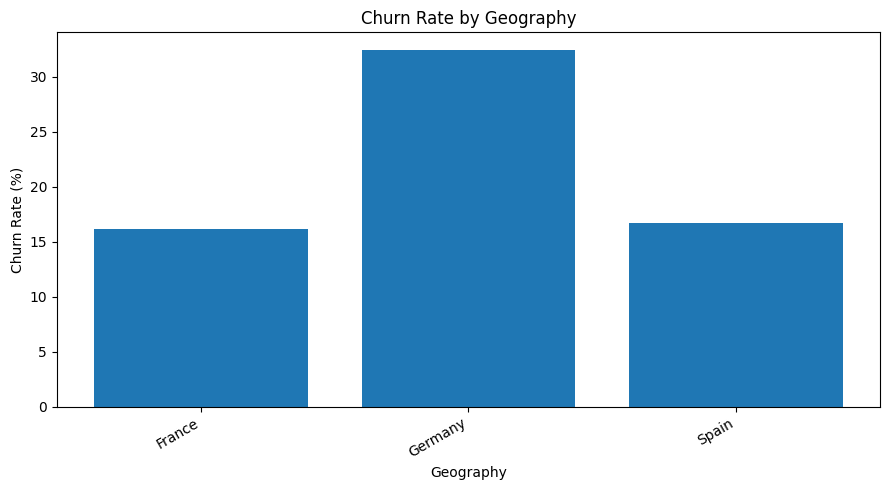


CHURN RATE BY GENDER


,Gender,Customers,Exited,Retained,Churn Rate (%)
0,Female,4543,1139,3404,25.07
1,Male,5457,898,4559,16.46


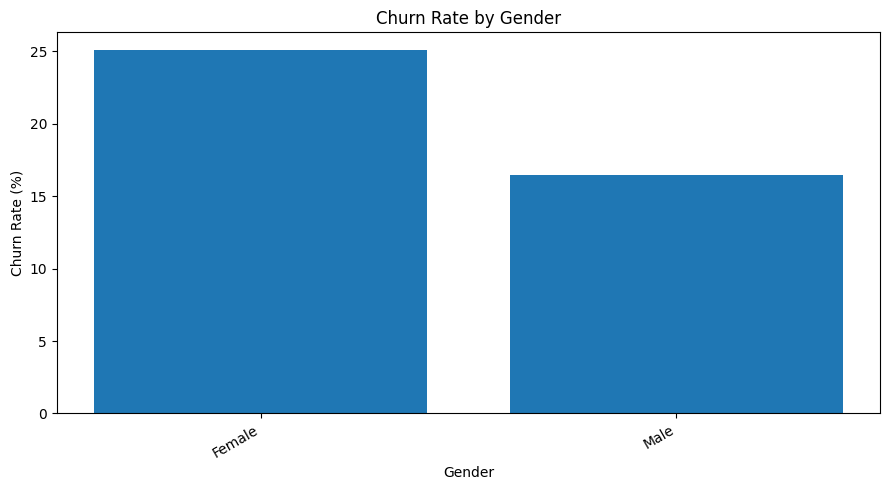


CHURN RATE BY NUMBER OF PRODUCTS


,NumOfProducts,Customers,Exited,Retained,Churn Rate (%)
0,1,5084,1409,3675,27.71
1,2,4590,348,4242,7.58
2,3,266,220,46,82.71
3,4,60,60,0,100.00


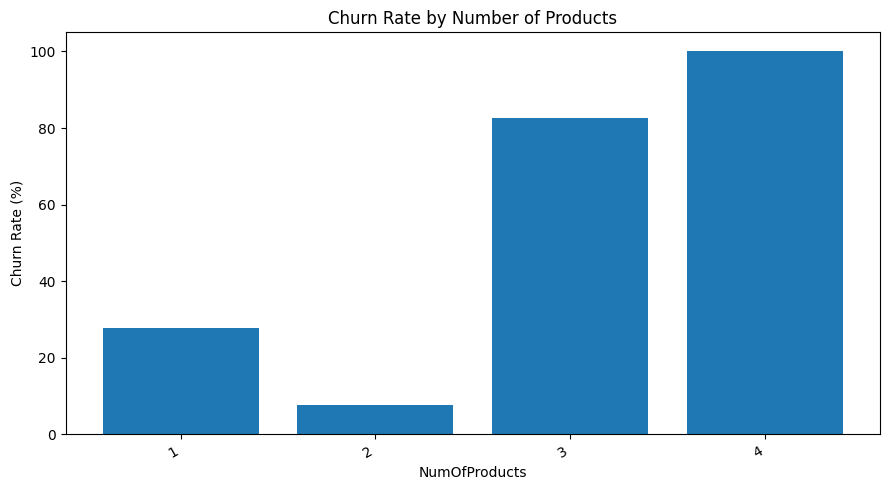


CHURN RATE BY ACTIVE MEMBER STATUS


,IsActiveMember,Customers,Exited,Retained,Churn Rate (%)
0,0,4849,1302,3547,26.85
1,1,5151,735,4416,14.27


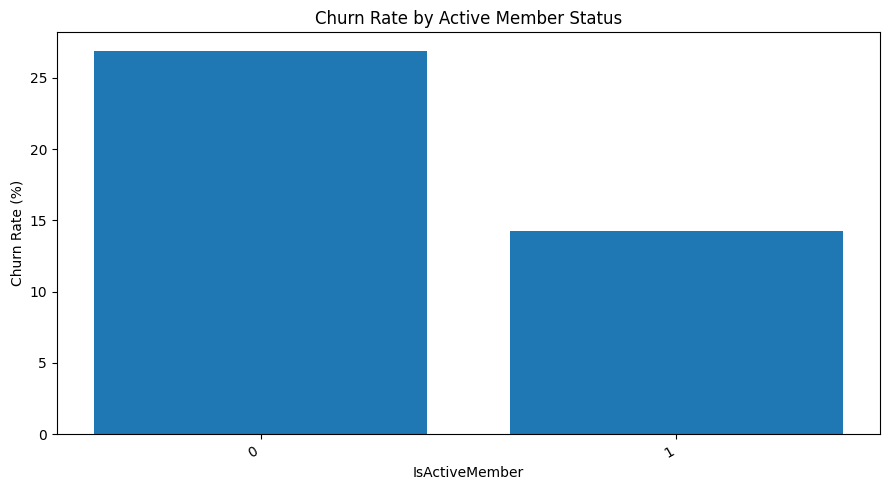


CHURN RATE BY AGE GROUP


,Age Group,Customers,Exited,Retained,Churn Rate (%)
0,Under 30,1641,124,1517,7.56
1,30-39,4346,473,3873,10.88
2,40-49,2618,806,1812,30.79
3,50+,1395,634,761,45.45


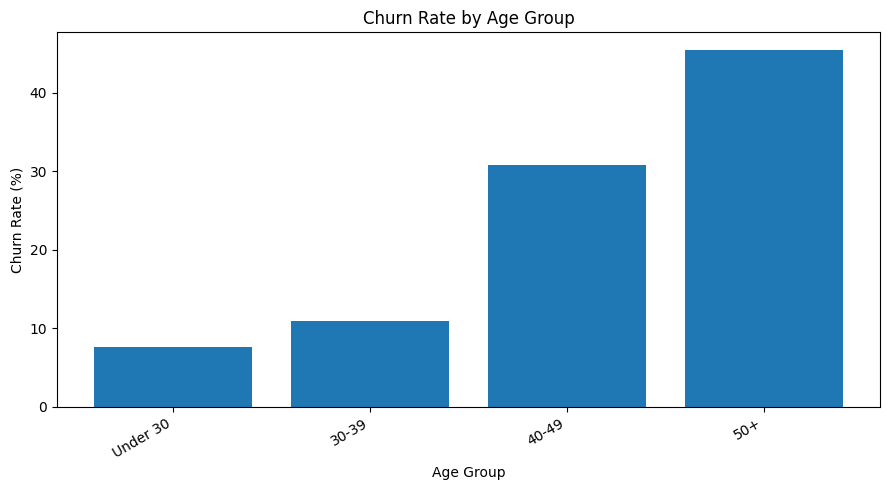


CHURN RATE BY CREDIT SCORE GROUP


,Credit Score Group,Customers,Exited,Retained,Churn Rate (%)
0,"(349.999, 584.0]",2534,556,1978,21.94
1,"(584.0, 652.0]",2501,526,1975,21.03
2,"(652.0, 718.0]",2502,455,2047,18.19
3,"(718.0, 850.0]",2463,500,1963,20.30


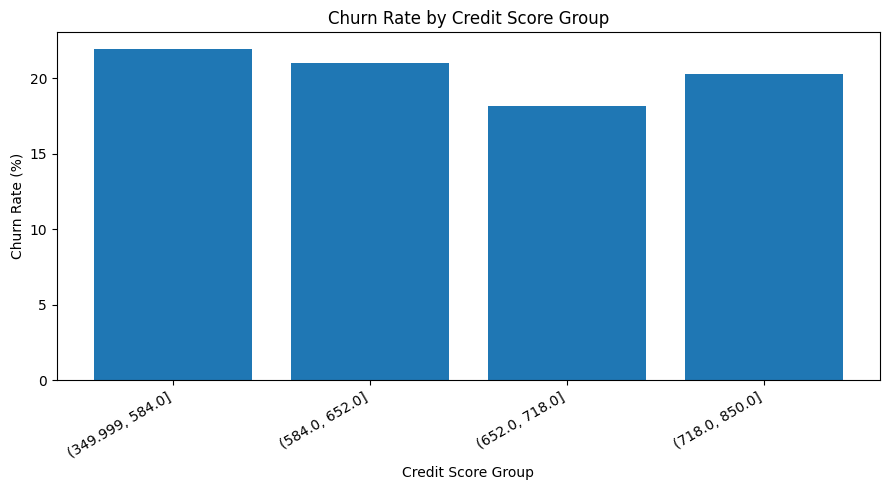


CHURN RATE BY TENURE GROUP


,Tenure Group,Customers,Exited,Retained,Churn Rate (%)
0,0-2 years,2496,528,1968,21.15
1,3-5 years,3010,625,2385,20.76
2,6+ years,4494,884,3610,19.67


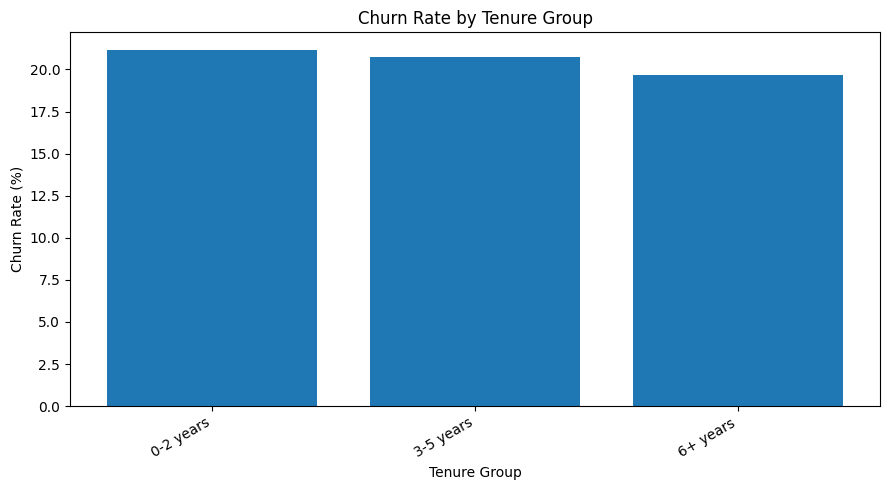


CHURN RATE BY BALANCE GROUP


,Balance Group,Customers,Exited,Retained,Churn Rate (%)
0,"(100181.975, 119839.69]",1596,437,1159,27.38
1,"(119839.69, 139512.29]",1595,404,1191,25.33
2,"(139512.29, 250898.09]",1596,367,1229,22.99
3,"(3768.689, 100181.975]",1596,329,1267,20.61
4,Zero balance,3617,500,3117,13.82


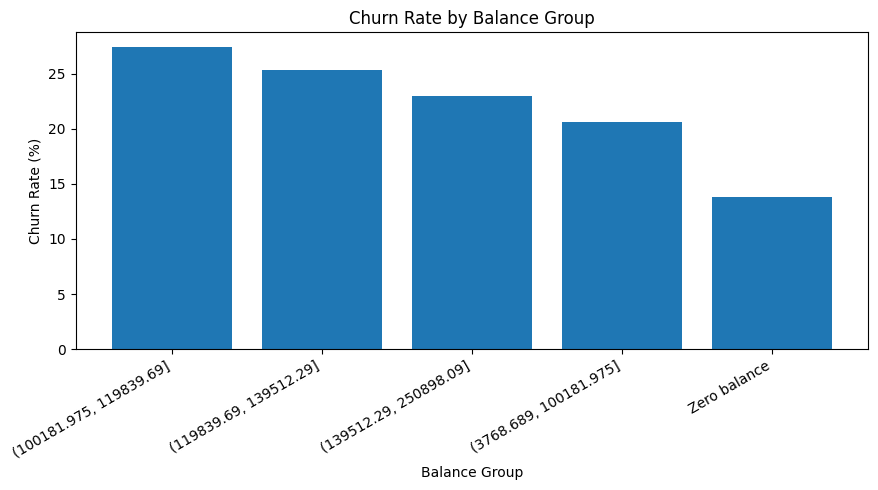


CHURN RATE BY SALARY GROUP


,Salary Group,Customers,Exited,Retained,Churn Rate (%)
0,"(11.579, 51002.11]",2500,500,2000,20.00
1,"(51002.11, 100193.915]",2500,495,2005,19.80
2,"(100193.915, 149388.248]",2500,503,1997,20.12
3,"(149388.248, 199992.48]",2500,539,1961,21.56


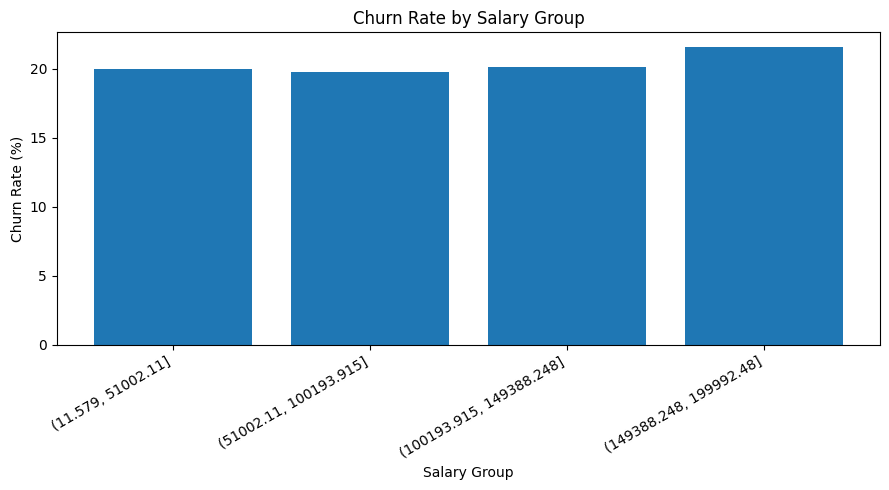


AVERAGE CHARACTERISTICS: RETAINED VS EXITED


Exited,Variable,Retained Customers,Exited Customers
0,Year,2.025000e+03,2.025000e+03
1,CustomerId,1.569117e+07,1.569005e+07
2,CreditScore,6.518532e+02,6.453515e+02
3,Age,3.740839e+01,4.483800e+01
4,Tenure,5.033279e+00,4.932744e+00
5,Balance,7.274530e+04,9.110854e+04
6,NumOfProducts,1.544267e+00,1.475209e+00
7,HasCrCard,7.071455e-01,6.990673e-01
8,IsActiveMember,5.545649e-01,3.608247e-01
9,EstimatedSalary,9.973839e+04,1.014657e+05



YEAR-WISE CHURN ANALYSIS


,Year,Customers,Exited,Churn Rate (%)
0,2025,10000,2037,20.37


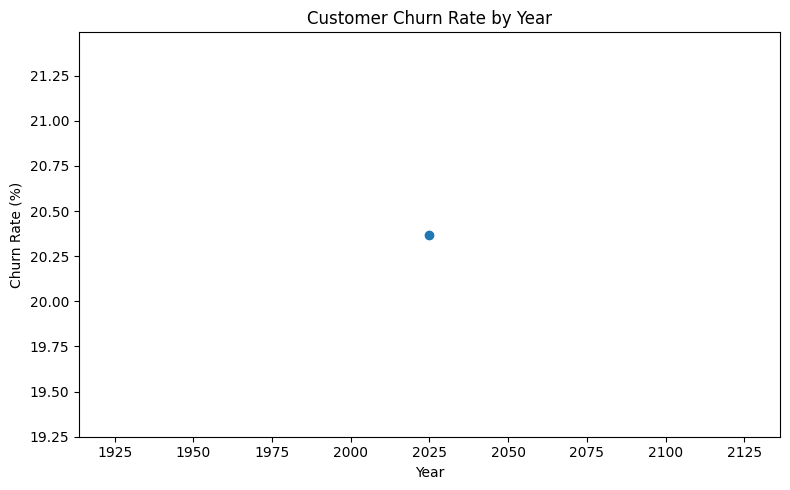


ANALYSIS COMPLETED SUCCESSFULLY
Excel results saved to: /content/Bank_Churn_Analysis_Results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ==========================================
# EUROPEAN BANK CUSTOMER CHURN ANALYSIS
# Google Colab - No Streamlit Required
# ==========================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# If required, install openpyxl for Excel export
%pip -q install openpyxl

# ------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------

# Use the CSV uploaded in Step 1
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("No CSV file found. Please run the upload cell first.")

file_path = csv_files[0]
df = pd.read_csv(file_path)

# Clean column names
df.columns = df.columns.astype(str).str.strip()

print("DATASET LOADED SUCCESSFULLY")
print("-" * 50)
print("File:", file_path)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn Names:")
print(df.columns.tolist())

display(df.head())

# ------------------------------------------
# 2. DATA QUALITY CHECK
# ------------------------------------------

print("\nDATA QUALITY REPORT")
print("-" * 50)

quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data Type": [str(df[c].dtype) for c in df.columns],
    "Missing Values": [df[c].isna().sum() for c in df.columns],
    "Unique Values": [df[c].nunique(dropna=True) for c in df.columns]
})

display(quality_report)

print("Exact duplicate rows:", df.duplicated().sum())

# Remove exact duplicate records
df = df.drop_duplicates().copy()

# ------------------------------------------
# 3. IDENTIFY CHURN COLUMN
# ------------------------------------------

column_lookup = {c.lower().replace("_", "").replace(" ", ""): c
                 for c in df.columns}

possible_churn_names = ["exited", "churn", "churned", "ischurned"]
churn_col = next(
    (column_lookup[name] for name in possible_churn_names
     if name in column_lookup),
    None
)

if churn_col is None:
    raise ValueError(
        "Churn column not found. Expected a column such as 'Exited'. "
        f"Available columns: {df.columns.tolist()}"
    )

# Convert common text labels to 0/1
if df[churn_col].dtype == "object":
    df[churn_col] = (
        df[churn_col].astype(str).str.strip().str.lower()
        .replace({
            "yes": "1", "true": "1", "churned": "1", "exited": "1",
            "no": "0", "false": "0", "retained": "0", "active": "0"
        })
    )

df[churn_col] = pd.to_numeric(df[churn_col], errors="coerce")
df = df[df[churn_col].isin([0, 1])].copy()
df[churn_col] = df[churn_col].astype(int)

if df.empty:
    raise ValueError("No valid 0/1 churn values were found.")

# Detect commonly used columns
def find_col(names):
    for name in names:
        key = name.lower().replace("_", "").replace(" ", "")
        if key in column_lookup:
            return column_lookup[key]
    return None

age_col = find_col(["Age"])
geo_col = find_col(["Geography", "Country", "Region"])
gender_col = find_col(["Gender", "Sex"])
credit_col = find_col(["CreditScore", "Credit_Score"])
balance_col = find_col(["Balance", "AccountBalance"])
tenure_col = find_col(["Tenure", "YearsWithBank"])
products_col = find_col(["NumOfProducts", "NumberOfProducts"])
active_col = find_col(["IsActiveMember", "ActiveMember"])
salary_col = find_col(["EstimatedSalary", "Salary"])
year_col = find_col(["Year"])

numeric_candidates = [
    age_col, credit_col, balance_col, tenure_col,
    products_col, active_col, salary_col, year_col
]

for col in numeric_candidates:
    if col and col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# ------------------------------------------
# 4. OVERALL CHURN STATISTICS
# ------------------------------------------

total_customers = len(df)
exited = int((df[churn_col] == 1).sum())
retained = int((df[churn_col] == 0).sum())

churn_rate = exited / total_customers * 100
retention_rate = retained / total_customers * 100

overall_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Exited Customers",
        "Retained Customers",
        "Churn Rate (%)",
        "Retention Rate (%)"
    ],
    "Value": [
        total_customers,
        exited,
        retained,
        round(churn_rate, 2),
        round(retention_rate, 2)
    ]
})

print("\nOVERALL CUSTOMER CHURN")
display(overall_summary)

# ------------------------------------------
# 5. CHURN DISTRIBUTION CHART
# ------------------------------------------

plt.figure(figsize=(7, 5))
plt.bar(
    ["Retained", "Exited"],
    [retained, exited]
)
plt.title("European Bank: Customer Churn Distribution")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# ------------------------------------------
# 6. SEGMENT ANALYSIS FUNCTION
# ------------------------------------------

segment_tables = {}

def analyze_segment(column, title, filename=None):
    if column is None or column not in df.columns:
        print(f"Skipped {title}: required column not found.")
        return

    temp = df[[column, churn_col]].dropna().copy()

    if temp.empty:
        print(f"Skipped {title}: no valid data.")
        return

    summary = (
        temp.groupby(column, observed=True)[churn_col]
        .agg(Customers="count", Exited="sum")
        .reset_index()
    )

    summary["Retained"] = summary["Customers"] - summary["Exited"]
    summary["Churn Rate (%)"] = (
        summary["Exited"] / summary["Customers"] * 100
    ).round(2)

    segment_tables[title] = summary

    print(f"\n{title.upper()}")
    display(summary)

    plt.figure(figsize=(9, 5))
    plt.bar(
        summary[column].astype(str),
        summary["Churn Rate (%)"]
    )
    plt.title(title)
    plt.xlabel(column)
    plt.ylabel("Churn Rate (%)")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# ------------------------------------------
# 7. GEOGRAPHY, GENDER AND PRODUCT ANALYSIS
# ------------------------------------------

analyze_segment(geo_col, "Churn Rate by Geography")
analyze_segment(gender_col, "Churn Rate by Gender")
analyze_segment(products_col, "Churn Rate by Number of Products")
analyze_segment(active_col, "Churn Rate by Active Member Status")

# ------------------------------------------
# 8. AGE GROUP ANALYSIS
# ------------------------------------------

if age_col:
    df["Age Group"] = pd.cut(
        df[age_col],
        bins=[0, 29, 39, 49, np.inf],
        labels=["Under 30", "30-39", "40-49", "50+"]
    )
    analyze_segment("Age Group", "Churn Rate by Age Group")

# ------------------------------------------
# 9. CREDIT SCORE GROUP ANALYSIS
# ------------------------------------------

if credit_col and df[credit_col].nunique() >= 2:
    df["Credit Score Group"] = pd.qcut(
        df[credit_col],
        q=4,
        duplicates="drop"
    )
    analyze_segment("Credit Score Group", "Churn Rate by Credit Score Group")

# ------------------------------------------
# 10. TENURE GROUP ANALYSIS
# ------------------------------------------

if tenure_col:
    df["Tenure Group"] = pd.cut(
        df[tenure_col],
        bins=[-1, 2, 5, np.inf],
        labels=["0-2 years", "3-5 years", "6+ years"]
    )
    analyze_segment("Tenure Group", "Churn Rate by Tenure Group")

# ------------------------------------------
# 11. BALANCE GROUP ANALYSIS
# ------------------------------------------

if balance_col:
    df["Balance Group"] = "Zero balance"
    positive = df[balance_col] > 0
    positive_values = df.loc[positive, balance_col]

    if positive_values.nunique() >= 2:
        try:
            df.loc[positive, "Balance Group"] = pd.qcut(
                positive_values,
                q=4,
                duplicates="drop"
            ).astype(str)
        except ValueError:
            df.loc[positive, "Balance Group"] = "Positive balance"
    elif positive.any():
        df.loc[positive, "Balance Group"] = "Positive balance"

    analyze_segment("Balance Group", "Churn Rate by Balance Group")

# ------------------------------------------
# 12. SALARY GROUP ANALYSIS
# ------------------------------------------

if salary_col and df[salary_col].nunique() >= 2:
    df["Salary Group"] = pd.qcut(
        df[salary_col],
        q=4,
        duplicates="drop"
    )
    analyze_segment("Salary Group", "Churn Rate by Salary Group")

# ------------------------------------------
# 13. RETAINED VS EXITED COMPARISON
# ------------------------------------------

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
numeric_columns = [c for c in numeric_columns if c != churn_col]

if numeric_columns:
    comparison = df.groupby(churn_col)[numeric_columns].mean().T
    comparison = comparison.rename(
        columns={0: "Retained Customers", 1: "Exited Customers"}
    )
    comparison.index.name = "Variable"
    comparison = comparison.reset_index()

    print("\nAVERAGE CHARACTERISTICS: RETAINED VS EXITED")
    display(comparison)
else:
    comparison = pd.DataFrame()

# ------------------------------------------
# 14. YEAR-WISE ANALYSIS, IF YEAR EXISTS
# ------------------------------------------

if year_col:
    yearly = (
        df.groupby(year_col, dropna=True)[churn_col]
        .agg(Customers="count", Exited="sum")
        .reset_index()
    )
    yearly["Churn Rate (%)"] = (
        yearly["Exited"] / yearly["Customers"] * 100
    ).round(2)

    print("\nYEAR-WISE CHURN ANALYSIS")
    display(yearly)

    plt.figure(figsize=(8, 5))
    plt.plot(
        yearly[year_col],
        yearly["Churn Rate (%)"],
        marker="o"
    )
    plt.title("Customer Churn Rate by Year")
    plt.xlabel("Year")
    plt.ylabel("Churn Rate (%)")
    plt.tight_layout()
    plt.show()
else:
    yearly = pd.DataFrame()

# ------------------------------------------
# 15. EXPORT RESULTS TO EXCEL
# ------------------------------------------

output_file = "/content/Bank_Churn_Analysis_Results.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    overall_summary.to_excel(
        writer, sheet_name="Overall Summary", index=False
    )
    quality_report.to_excel(
        writer, sheet_name="Data Quality", index=False
    )

    if not comparison.empty:
        comparison.to_excel(
            writer, sheet_name="Retained vs Exited", index=False
        )

    if not yearly.empty:
        yearly.to_excel(
            writer, sheet_name="Yearly Analysis", index=False
        )

    for index, (name, table) in enumerate(segment_tables.items(), start=1):
        sheet_name = f"Segment {index}"
        table.to_excel(writer, sheet_name=sheet_name, index=False)

print("\nANALYSIS COMPLETED SUCCESSFULLY")
print("Excel results saved to:", output_file)

# Download the Excel workbook to your computer
from google.colab import files
files.download(output_file)
